/var/folders/yy/_bjr15r108z7k9ls0mz3njlr0000gn/T/ipykernel_36284/3067811109.py:103: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  days = dates.dayofyear.to_numpy()
/var/folders/yy/_bjr15r108z7k9ls0mz3njlr0000gn/T/ipykernel_36284/3067811109.py:103: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  days = dates.dayofyear.to_numpy()
/var/folders/yy/_bjr15r108z7k9ls0mz3njlr0000gn/T/ipykernel_36284/3067811109.py:103: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  days = dates.dayofyear.to_numpy()


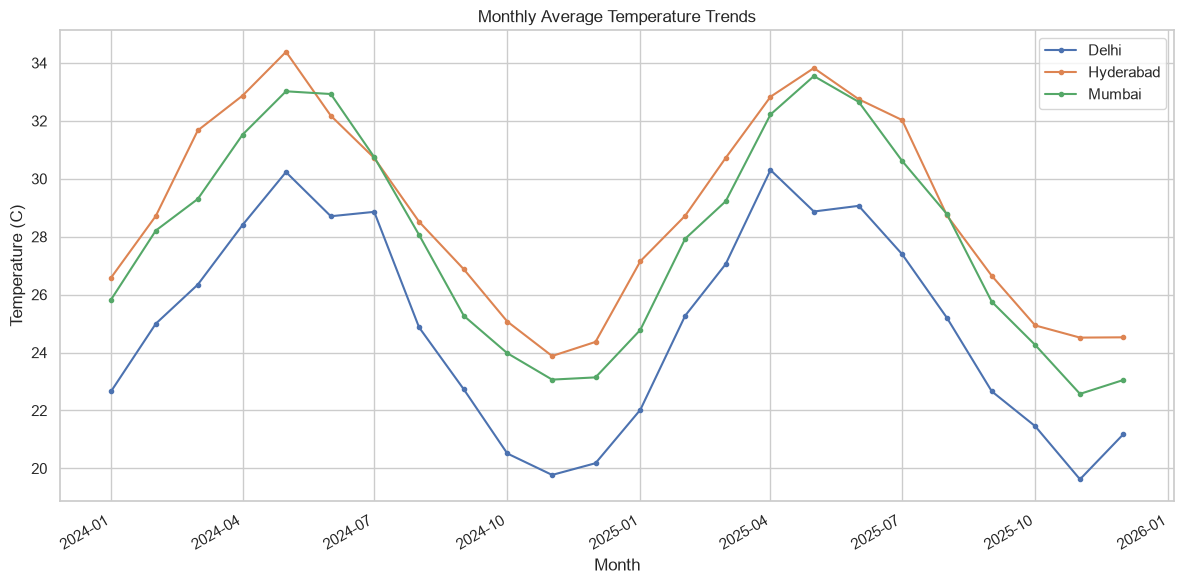

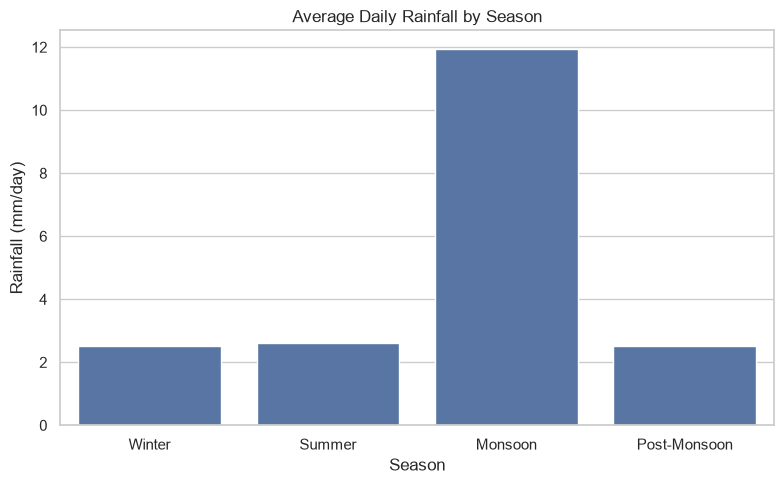

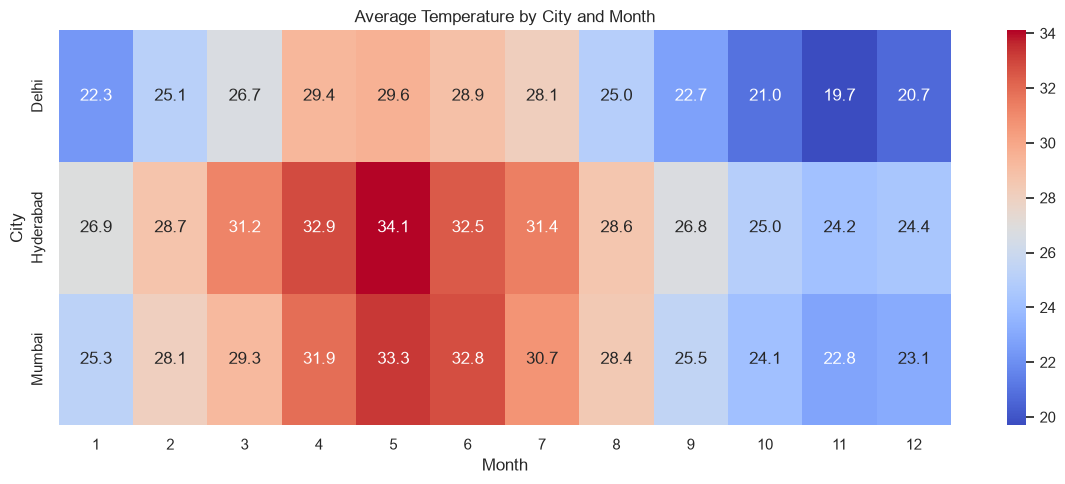

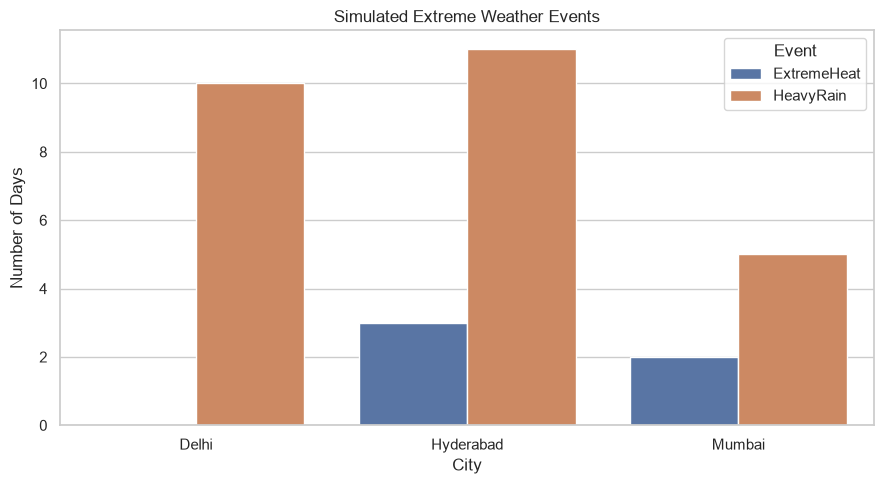

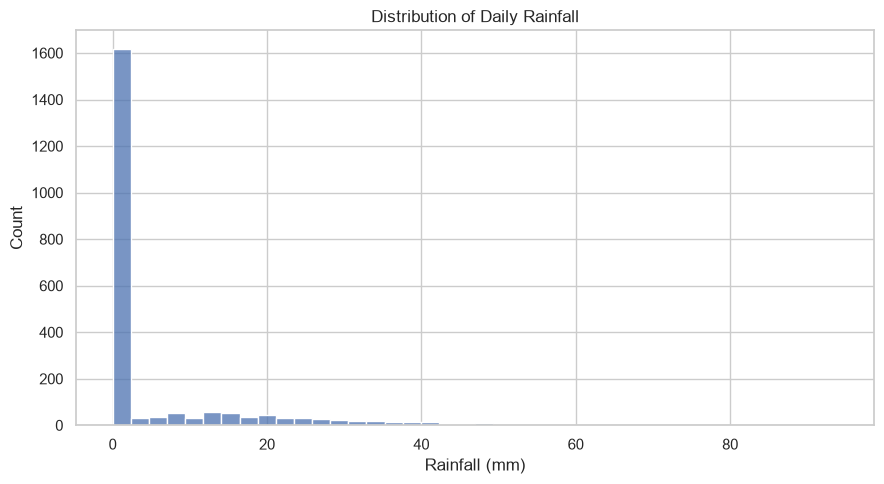


PROJECT 3 COMPLETED
Observations: 2193
Cities: 3
Warmest City: Hyderabad
Wettest City: Hyderabad
Statistical Test p-value: 1.4322502276120974e-49
Charts: 5
PDF: /Users/ansifrasak/Downloads/Main Projects /The_project_Developers_ARENA/weather-data-analysis/project3_weather_analysis/reports/weather_analysis_report.pdf
Saved in: /Users/ansifrasak/Downloads/Main Projects /The_project_Developers_ARENA/weather-data-analysis/project3_weather_analysis


In [1]:

# ============================================================
# PROJECT 3: WEATHER DATA ANALYSIS
# ONE-CELL COMPLETE PROJECT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak
)
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from xml.sax.saxutils import escape

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(43)

# 1. PROJECT SETUP
base = Path.cwd()
if base.name == "notebooks":
    base = base.parent
if base.name.startswith("project"):
    base = base.parent
if (base / "Data_Analysis_Portfolio").is_dir():
    base = base / "Data_Analysis_Portfolio"

project_name = "project3_weather_analysis"
root = base / project_name

for name in ["data", "notebooks", "reports",
             "visualizations", "docs", "src"]:
    (root / name).mkdir(parents=True, exist_ok=True)

plots = []

def save_chart(fig, filename):
    fig.tight_layout()
    path = root / "visualizations" / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plots.append(path)
    plt.show()
    plt.close(fig)

def create_report(title, sections, filename):
    styles = getSampleStyleSheet()
    story = [
        Paragraph(escape(title), styles["Title"]),
        Paragraph("Simulated Weather Dataset", styles["Italic"]),
        Spacer(1, 15)
    ]

    for heading, paragraphs in sections.items():
        story.append(Paragraph(
            escape(heading), styles["Heading2"]
        ))
        for content in paragraphs:
            story.append(Paragraph(
                escape(str(content)), styles["BodyText"]
            ))
            story.append(Spacer(1, 8))

    for chart in plots:
        story.append(PageBreak())
        story.append(Paragraph(
            escape(chart.stem.replace("_", " ").title()),
            styles["Heading2"]
        ))
        img = Image(str(chart))
        scale = min(
            440 / img.drawWidth,
            620 / img.drawHeight
        )
        img.drawWidth *= scale
        img.drawHeight *= scale
        story.append(img)

    pdf = root / "reports" / filename
    SimpleDocTemplate(
        str(pdf), pagesize=A4, title=title
    ).build(story)
    return pdf

# 2. GENERATE SYNTHETIC WEATHER DATA
dates = pd.date_range(
    "2024-01-01", "2025-12-31", freq="D"
)

city_temperatures = {
    "Hyderabad": 29,
    "Delhi": 25,
    "Mumbai": 28
}

frames = []

for city, baseline in city_temperatures.items():
    count = len(dates)

    days = dates.dayofyear.to_numpy()
    months = dates.month.to_numpy()

    seasonal = 5 * np.sin(
        2 * np.pi * (days - 50) / 365
    )

    monsoon = np.isin(months, [6, 7, 8, 9])

    rain_probability = np.where(
        monsoon, 0.58, 0.12
    )

    rainy = rng.random(count) < rain_probability

    rainfall = np.where(
        rainy,
        rng.gamma(2.2, 9.5, count),
        0
    )

    temperature = (
        baseline
        + seasonal
        + rng.normal(0, 2.8, count)
        - rainfall * 0.025
    )

    humidity = np.clip(
        48
        + 13 * monsoon
        + 0.5 * rainfall
        + rng.normal(0, 9, count),
        15, 100
    )

    frames.append(pd.DataFrame({
        "Date": dates,
        "City": city,
        "TemperatureC": temperature.round(2),
        "RainfallMM": rainfall.round(2),
        "HumidityPct": humidity.round(2)
    }))

df_raw = pd.concat(frames, ignore_index=True)

# Insert practice-quality problems
df_raw.loc[0, "TemperatureC"] = np.nan
df_raw.loc[1, "RainfallMM"] = -10
df_raw.loc[2, "HumidityPct"] = 130
df_raw = pd.concat(
    [df_raw, df_raw.iloc[[3]]],
    ignore_index=True
)

df_raw.to_csv(
    root / "data" / "weather_raw.csv",
    index=False
)

# 3. CLEAN DATA
duplicates = df_raw.duplicated(
    subset=["City", "Date"]
).sum()

df = (
    df_raw.drop_duplicates(["City", "Date"])
    .sort_values(["City", "Date"])
    .copy()
)

df["Date"] = pd.to_datetime(df["Date"])

numeric_cols = [
    "TemperatureC", "RainfallMM", "HumidityPct"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )

df.loc[
    ~df["TemperatureC"].between(-20, 55),
    "TemperatureC"
] = np.nan

df.loc[
    df["RainfallMM"] < 0,
    "RainfallMM"
] = np.nan

df.loc[
    ~df["HumidityPct"].between(0, 100),
    "HumidityPct"
] = np.nan

for col in numeric_cols:
    df[col] = df.groupby("City")[col].transform(
        lambda x: x.interpolate(
            limit_direction="both"
        ).fillna(x.median())
    )

month = df["Date"].dt.month

df["Season"] = np.select(
    [
        month.isin([6, 7, 8, 9]),
        month.isin([12, 1, 2]),
        month.isin([3, 4, 5])
    ],
    ["Monsoon", "Winter", "Summer"],
    default="Post-Monsoon"
)

df["Month"] = df["Date"].dt.to_period(
    "M"
).astype(str)

# Illustrative extreme-event thresholds
df["ExtremeHeat"] = df["TemperatureC"] >= 40
df["HeavyRain"] = df["RainfallMM"] >= 50

assert df[["City", "Date"]].duplicated().sum() == 0
assert df[numeric_cols].notna().all().all()
assert df["RainfallMM"].ge(0).all()
assert df["HumidityPct"].between(0, 100).all()

df.to_csv(
    root / "data" / "weather_cleaned.csv",
    index=False
)

# 4. STATISTICAL ANALYSIS
city_summary = df.groupby("City").agg(
    AverageTemp=("TemperatureC", "mean"),
    MaxTemp=("TemperatureC", "max"),
    TotalRainfall=("RainfallMM", "sum"),
    AverageHumidity=("HumidityPct", "mean"),
    HeatDays=("ExtremeHeat", "sum"),
    HeavyRainDays=("HeavyRain", "sum")
)

monthly_summary = df.groupby(
    ["Month", "City"], as_index=False
).agg(
    AverageTemp=("TemperatureC", "mean"),
    TotalRainfall=("RainfallMM", "sum")
)

season_summary = df.groupby("Season").agg(
    AverageTemperature=("TemperatureC", "mean"),
    AverageDailyRainfall=("RainfallMM", "mean"),
    AverageHumidity=("HumidityPct", "mean")
)

correlation_matrix = df[
    numeric_cols
].corr()

temperature_humidity_corr = df[
    "TemperatureC"
].corr(df["HumidityPct"])

monsoon_rain = df.loc[
    df["Season"] == "Monsoon", "RainfallMM"
]

other_rain = df.loc[
    df["Season"] != "Monsoon", "RainfallMM"
]

t_stat, p_value = stats.ttest_ind(
    monsoon_rain,
    other_rain,
    equal_var=False
)

city_summary.to_csv(
    root / "reports" / "city_statistics.csv"
)
season_summary.to_csv(
    root / "reports" / "season_statistics.csv"
)
monthly_summary.to_csv(
    root / "reports" / "monthly_statistics.csv",
    index=False
)
correlation_matrix.to_csv(
    root / "reports" / "correlation_matrix.csv"
)

# 5. CHART 1: MONTHLY TEMPERATURE TREND
fig, ax = plt.subplots(figsize=(12, 6))

for city, group in monthly_summary.groupby("City"):
    ax.plot(
        pd.to_datetime(group["Month"]),
        group["AverageTemp"],
        marker=".",
        label=city
    )

ax.set_title("Monthly Average Temperature Trends")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (C)")
ax.legend()
fig.autofmt_xdate()
save_chart(fig, "01_temperature_trends.png")

# 6. CHART 2: SEASONAL RAINFALL
season_order = [
    "Winter", "Summer", "Monsoon", "Post-Monsoon"
]

rain_by_season = (
    df.groupby("Season")["RainfallMM"]
    .mean()
    .reindex(season_order)
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    x=rain_by_season.index,
    y=rain_by_season.values,
    ax=ax
)
ax.set_title("Average Daily Rainfall by Season")
ax.set_ylabel("Rainfall (mm/day)")
ax.set_xlabel("Season")
save_chart(fig, "02_seasonal_rainfall.png")

# 7. CHART 3: TEMPERATURE HEATMAP
temperature_matrix = (
    df.assign(MonthNumber=df["Date"].dt.month)
    .pivot_table(
        index="City",
        columns="MonthNumber",
        values="TemperatureC",
        aggfunc="mean"
    )
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(
    temperature_matrix,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    ax=ax
)
ax.set_title("Average Temperature by City and Month")
ax.set_xlabel("Month")
save_chart(fig, "03_temperature_heatmap.png")

# 8. CHART 4: EXTREME EVENT COUNTS
extreme_summary = (
    df.groupby("City")[
        ["ExtremeHeat", "HeavyRain"]
    ]
    .sum()
    .reset_index()
    .melt(
        id_vars="City",
        var_name="Event",
        value_name="Days"
    )
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=extreme_summary,
    x="City",
    y="Days",
    hue="Event",
    ax=ax
)
ax.set_title("Simulated Extreme Weather Events")
ax.set_ylabel("Number of Days")
save_chart(fig, "04_extreme_weather.png")

# 9. CHART 5: RAINFALL DISTRIBUTION
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    df["RainfallMM"],
    bins=40,
    ax=ax
)
ax.set_title("Distribution of Daily Rainfall")
ax.set_xlabel("Rainfall (mm)")
save_chart(fig, "05_rainfall_distribution.png")

# 10. INSIGHTS AND RECOMMENDATIONS
warmest_city = city_summary[
    "AverageTemp"
].idxmax()

wettest_city = city_summary[
    "TotalRainfall"
].idxmax()

wettest_season = season_summary[
    "AverageDailyRainfall"
].idxmax()

findings = [
    f"Total daily city observations: {len(df):,}.",
    f"Warmest city on average: {warmest_city}.",
    f"Highest total rainfall: {wettest_city}.",
    f"Highest average daily rainfall season: "
    f"{wettest_season}.",
    f"Temperature-humidity correlation: "
    f"{temperature_humidity_corr:.3f}.",
    f"Extreme heat observations: "
    f"{int(df['ExtremeHeat'].sum())}.",
    f"Heavy rainfall observations: "
    f"{int(df['HeavyRain'].sum())}.",
    f"Exploratory monsoon rainfall Welch test "
    f"p-value: {p_value:.5g}."
]

recommendations = [
    "Use city-specific monitoring rather than "
    "a single threshold for all regions.",
    "Monitor periods with high rainfall or high "
    "temperatures for operational preparedness.",
    "Compare historical observations with verified "
    "weather agency data before making forecasts.",
    "Use long-term observations for genuine "
    "climate-change analysis."
]

sections = {
    "Executive Summary": [
        "This project analyzes simulated daily weather "
        "observations for Hyderabad, Delhi, and Mumbai "
        "over 2024 and 2025."
    ],
    "Methodology": [
        "Datetime processing, duplicate removal, "
        "range validation, interpolation, grouping, "
        "trend analysis, correlation, and Welch t-test."
    ],
    "Data Quality": [
        f"Removed {duplicates} duplicated city-date rows.",
        "Invalid weather values were treated as missing "
        "and interpolated for the simulated exercise."
    ],
    "Key Findings": findings,
    "Recommendations": recommendations,
    "Limitations": [
        "All observations are simulated.",
        "Season definitions are illustrative.",
        "Extreme event thresholds are illustrative.",
        "A two-year simulated dataset does not "
        "establish long-term climate trends.",
        "Correlations and t-tests are not "
        "evidence of physical causation."
    ]
}

pdf = create_report(
    "Weather Data Analysis",
    sections,
    "weather_analysis_report.pdf"
)

# 11. DOCUMENTATION
readme = f"""# Weather Data Analysis

## Overview
Simulated temperature, rainfall and humidity analysis.

## Coverage
- Cities: Hyderabad, Delhi, Mumbai
- Period: 2024-2025
- Observations: {len(df):,}

## Methods
Data cleaning, interpolation, aggregation, correlation,
seasonality analysis, trend analysis and Welch t-test.

## Findings
- Warmest city: {warmest_city}
- Wettest city: {wettest_city}
- Wettest season: {wettest_season}

## Reproduce
Install requirements and run the notebook's single cell.

## Outputs
- data/weather_raw.csv
- data/weather_cleaned.csv
- reports/weather_analysis_report.pdf
- reports/statistical CSV summaries
- visualizations/ (five PNG charts)

## Limitations
Synthetic observations, not real meteorological records.
"""

(root / "README.md").write_text(
    readme, encoding="utf-8"
)

(root / "requirements.txt").write_text(
    "pandas\nnumpy\nmatplotlib\nseaborn\nscipy\nreportlab\n",
    encoding="utf-8"
)

(root / "docs" / "methodology.md").write_text(
    "Simulated weather observations with range checks, "
    "interpolation, four illustrative Indian seasons, "
    "and exploratory hypothesis testing.\n",
    encoding="utf-8"
)

print("\n" + "="*60)
print("PROJECT 3 COMPLETED")
print("="*60)
print("Observations:", len(df))
print("Cities:", df["City"].nunique())
print("Warmest City:", warmest_city)
print("Wettest City:", wettest_city)
print("Statistical Test p-value:", p_value)
print("Charts:", len(plots))
print("PDF:", pdf)
print("Saved in:", root)
